# CBIM Problem Canvas
## Credit Pre-Screening Engine — Loan Intake Optimisation

### 1. Situation (S)

A mid-sized private bank in India offers unsecured personal loans to salaried employees, self-employed professionals, business owners, and gig/contract workers. The bank receives approximately 3,000 loan applications per month, and each application currently undergoes a manual credit review that takes an analyst around 25 minutes.

### 2. Complication (C)

Manual credit reviews consume significant analyst time, including for applications that may have clear indicators of decline, such as very low credit scores or high existing EMI obligations. As a result, analysts have less time to focus on applications requiring human judgement, potentially increasing review delays and reducing operational efficiency. The bank needs to determine whether historical application decisions can support safe and reliable preliminary screening without unfairly affecting applicants.

### 3. Question (Q)

Using six months of historical loan application data and credit decisions, how can a machine-learning-based pre-screening engine reduce the manual review workload by identifying clear-cut declines and potential approvals while meeting the bank's risk limits? Which model and decision thresholds should the bank adopt to balance operational efficiency, prediction reliability, explainability, and fairness?

### 4. SSOT (Single Source of Truth)

The provided `MUC02_Credit_PreScreening_Dataset.csv` is the primary source of truth for this analysis. It contains 12,000 simulated loan applications received between April and September 2026. Each row represents one loan application, and the `decision` column records the final historical decision made by the bank's credit team: `Approved` or `Declined`.

The historical decision is the target variable for supervised learning. It represents the bank's previous decisions, not independently verified evidence of actual loan repayment or default. Therefore, the model will learn historical decision patterns and must be evaluated carefully before being considered for operational use.

### 5. Success Definition

The pre-screening engine will be evaluated against the following business and modelling criteria:

- **Auto-decline risk limit:** No more than 5% of applications in the auto-decline lane may be applications historically approved by the credit team.
- **Fast-track risk limit:** No more than 5% of applications in the fast-track lane may be applications historically declined by the credit team.
- **Operational efficiency:** Maximise the number of applications moved out of the manual review queue while satisfying both risk limits.
- **Baseline performance:** Build and evaluate a Logistic Regression model using accuracy, confusion matrix, precision, and recall for the Declined class.
- **Model comparison:** Compare Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting using 5-fold StratifiedKFold cross-validation on the training set. Select and evaluate a suitable model using both performance and explainability.
- **Fairness assessment:** Examine historical approval rates and model auto-decline outcomes by gender, including potential proxy effects from other features.
- **Validation and reliability:** Use a stratified train-test split, prevent data leakage through appropriate preprocessing pipelines, and evaluate the final model on held-out test data.

The model's success will be determined by how safely and effectively it supports preliminary screening, rather than accuracy alone. Its predictions will be decision-support inputs, not the sole basis for final loan approval or rejection.

### 6. Primary Stakeholder

The **Credit Policy Analyst** is the primary stakeholder. She must assess the historical data, compare the models, recommend suitable decision thresholds, and present a defensible proposal to the Head of Retail Lending.

Other stakeholders include credit analysts whose manual workload may change, loan applicants affected by screening decisions, the bank's credit-risk and compliance teams, and business management responsible for operational efficiency and responsible lending practices.

The recommended system must balance workload reduction with risk control, explainability, fairness, and human oversight.

## Step 5.1 Load, Inspect and Clean

### 5.1.1 Load Libraries and Dataset

The first step is to import the libraries required for data manipulation, numerical calculations, and visualisation. I will load the provided CSV file into a Pandas DataFrame and create a working copy so that the original dataset remains unchanged.

The dataset will be inspected before making any cleaning decisions. This ensures that each transformation is based on the observed data and can be justified clearly.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset
df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

# Create a working copy
df_clean = df.copy()

# Display the first five rows
display(df_clean.head())

,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


The dataset was loaded successfully into a Pandas DataFrame. The first five records provide an initial view of the application fields, including applicant characteristics, financial information, and the historical credit decision.

The original DataFrame is preserved as `df`, while `df_clean` will be used for inspection and subsequent data preparation.

### 5.1.2 Inspect Dataset Shape and Data Types

I will inspect the number of rows and columns, column names, data types, and non-null counts. This will help identify the dataset structure, columns with missing values, and any data types that need correction before analysis.

In [2]:
# Check the number of rows and columns
print("Dataset shape:", df_clean.shape)

# Display column names
print("\nColumn names:")
print(df_clean.columns.tolist())

# Inspect data types and non-null counts
print("\nDataset information:")
df_clean.info()

Dataset shape: (12000, 19)

Column names:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   m

The dataset contains 12,000 rows and 19 columns. Each row represents a loan application.

The dataset includes numerical variables, categorical variables, an application identifier, an application date, and the historical decision target. The application_date column should be stored as a datetime type rather than text.

The data types and non-null counts will guide the next inspection steps. No records are removed at this stage.

-------------------------------------------------------------------------------------------------------------------------

### 5.1.3 Identify Missing Values

Missing values can affect statistical analysis and model training. I will calculate the number and percentage of missing values in each column.

This inspection will identify which columns need further investigation. I will not fill or remove missing values until their meaning and appropriate treatment have been established.

In [3]:
# Count missing values in each column
missing_count = df_clean.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

# Create a missing-value summary
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Display columns with missing values
display(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values("Missing_Count", ascending=False)
)

,Missing_Count,Missing_Percentage
credit_score,1039,8.66
monthly_income,441,3.68


#### Findings and Interpretation

The initial dataset inspection identified missing values in monthly_income and credit_score.

The monthly_income column contains 441 missing values, while credit_score contains 1,039 missing values. These represent approximately 3.68% and 8.66% of the 12,000 applications, respectively.

The two columns require separate investigations because missing income may require imputation, whereas a missing credit score may have a meaningful business explanation.

-----------------------------------------------------------------------------------------------------------------------------

### 5.1.4 Investigate Missing Monthly Income

The monthly_income column contains missing values. Before selecting an imputation method, I will determine which employment types have the most missing income records.

Income distributions can differ between salaried employees, self-employed professionals, business owners, and gig/contract workers. Understanding this distribution will help determine whether employment-type-specific median imputation is appropriate.

In [4]:
# Count missing income records by employment type
missing_income_by_job = (
    df_clean.loc[df_clean["monthly_income"].isna()]
    .groupby("employment_type")
    .size()
    .sort_values(ascending=False)
)

display(
    missing_income_by_job.rename(
        "Missing_Income_Count"
    ).to_frame()
)

,Missing_Income_Count
employment_type,
Business Owner,227
Self-Employed Professional,154
Salaried,49
Gig / Contract,11


#### Findings and Interpretation

The missing monthly_income values are distributed across the employment types as follows:

- Business Owner: 227
- Self-Employed Professional: 154
- Salaried: 49
- Gig / Contract: 11

Business owners and self-employed professionals account for most of the missing income records. This suggests that income imputation should consider differences between employment groups rather than automatically using one overall statistic.

The next step is to compare income statistics across employment types before finalising the imputation strategy.

-------------------------------------------------------------------------------------------------------------------------------

#### Compare Income Statistics by Employment Type

I will calculate the count, median, mean, minimum, and maximum monthly income for each employment type. Comparing the mean and median will help identify potential income skewness and determine whether median imputation is a sensible choice.

In [5]:
# Compare income statistics across employment types
income_by_job = (
    df_clean.groupby("employment_type")["monthly_income"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

display(income_by_job)

,count,median,mean,min,max
employment_type,,,,,
Business Owner,1522,69500.0,79441.52,12000.0,330000.0
Gig / Contract,1755,28000.0,32152.14,12000.0,170000.0
Salaried,7008,50000.0,58827.34,12000.0,1656000.0
Self-Employed Professional,1274,75000.0,84443.09,12000.0,349000.0


#### Cleaning Decision: Missing Monthly Income

I will use the median monthly income for the corresponding employment type as the proposed imputation strategy. This approach accounts for differences in typical income across employment groups and is less sensitive to unusually high incomes than mean imputation.

The actual imputation will be performed within the modelling preprocessing pipeline, using training data only. This prevents information from the test set from influencing the imputation values.

Until the pipeline is built, the missing values will remain unchanged in the working DataFrame. This preserves the original evidence and avoids performing premature preprocessing.

--------------------------------------------------------------------------------------------------------------------------------

### 5.1.5 Investigate Missing Credit Scores

The credit_score column contains missing values. These records must not be dropped automatically because the absence of a credit score may indicate that an applicant has no established credit history.

I will examine credit_history_months for applicants whose credit_score is missing. This will help determine whether the missing values are consistent with new-to-credit applicants or indicate a potential data-quality issue.

In [6]:
# Select applicants with missing credit scores
missing_score_rows = df_clean.loc[
    df_clean["credit_score"].isna()
]

# Examine their credit history
history_check = (
    missing_score_rows["credit_history_months"]
    .value_counts(dropna=False)
    .rename_axis("Credit_History_Months")
    .reset_index(name="Applicant_Count")
)

display(history_check)

# Verify whether all have zero credit history
all_zero_history = (
    missing_score_rows["credit_history_months"]
    .eq(0)
    .all()
)

print(
    "All missing-score applicants have zero credit history:",
    all_zero_history
)

,Credit_History_Months,Applicant_Count
0,0,1039


All missing-score applicants have zero credit history: True


#### Findings and Interpretation

The inspection shows that all 1,039 applicants with missing credit scores have credit_history_months equal to zero.

This is consistent with applicants who have no established credit history, commonly described as new-to-credit (NTC) applicants. Their missing credit scores therefore have a meaningful interpretation and should not automatically be treated as ordinary data-entry errors.

Dropping these records would remove an entire applicant segment and could introduce selection bias into the analysis.

#### Cleaning Decision: Missing Credit Scores

I will retain all applicants with missing credit scores. In Step 5.3, I will create an is_ntc indicator that equals 1 when credit_score is missing and 0 otherwise.

For model training, missing credit scores will be imputed using the median calculated from the training data. The is_ntc feature will preserve the distinction between applicants with no established credit history and applicants with an observed score.

I will not replace missing scores with zero because zero is outside the documented credit-score range of 300–900. The combination of median imputation and an NTC indicator allows the model to process numerical scores without losing the business meaning of missingness.

--------------------------------------------------------------------------------------------------------------------------------

### 5.1.6 Investigate Unusually High Monthly Income

The assignment highlights that a small number of monthly_income values appear implausibly high for monthly income.

I will examine the descriptive statistics, upper percentiles, and highest-income records. I will also visualise the distribution to understand the extent of the extreme values.

High income is not automatically an error. The investigation must distinguish potentially incorrect entries from legitimate high-income applicants before any correction or removal is considered.

In [7]:
# Inspect monthly income distribution
income_summary = df_clean["monthly_income"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.995]
)

display(income_summary.to_frame())

,monthly_income
count,1.155900e+04
mean,6.031486e+04
std,4.889083e+04
min,1.200000e+04
90%,1.060000e+05
95%,1.300000e+05
99%,1.910000e+05
99.5%,2.342100e+05
max,1.656000e+06


In [8]:
# Display the 15 highest monthly income records
display(
    df_clean.nlargest(15, "monthly_income")[
        [
            "application_id",
            "employment_type",
            "monthly_income",
            "existing_emi",
            "credit_score",
            "credit_history_months",
            "loan_amount",
            "decision"
        ]
    ]
)

,application_id,employment_type,monthly_income,existing_emi,credit_score,credit_history_months,loan_amount,decision
1467,APP101468,Salaried,1656000.0,16500.0,718.0,118,925000.0,Declined
300,APP100301,Salaried,1254000.0,0.0,NaN,0,240000.0,Approved
2493,APP102494,Salaried,1212000.0,23500.0,718.0,240,600000.0,Approved
589,APP100590,Salaried,1068000.0,13500.0,700.0,106,600000.0,Declined
9849,APP109850,Salaried,990000.0,21000.0,633.0,104,260000.0,Declined
1848,APP101849,Salaried,984000.0,0.0,NaN,0,500000.0,Approved
2488,APP102489,Salaried,972000.0,0.0,695.0,204,310000.0,Approved
4010,APP104011,Salaried,900000.0,4000.0,789.0,287,580000.0,Approved
4898,APP104899,Salaried,870000.0,4500.0,682.0,189,645000.0,Declined
9261,APP109262,Salaried,702000.0,0.0,740.0,87,495000.0,Approved


#### Visualise the Monthly Income Distribution

I will plot the distribution of monthly_income to understand where most applications fall and how extreme values affect the overall distribution. Counts will be displayed above the histogram bars so that the number of applications in each income interval is visible.

Because the income values span a wide range, I will also use a log-scale visualisation to examine the distribution more clearly. The plots will support investigation, but will not by themselves establish that any value is incorrect.

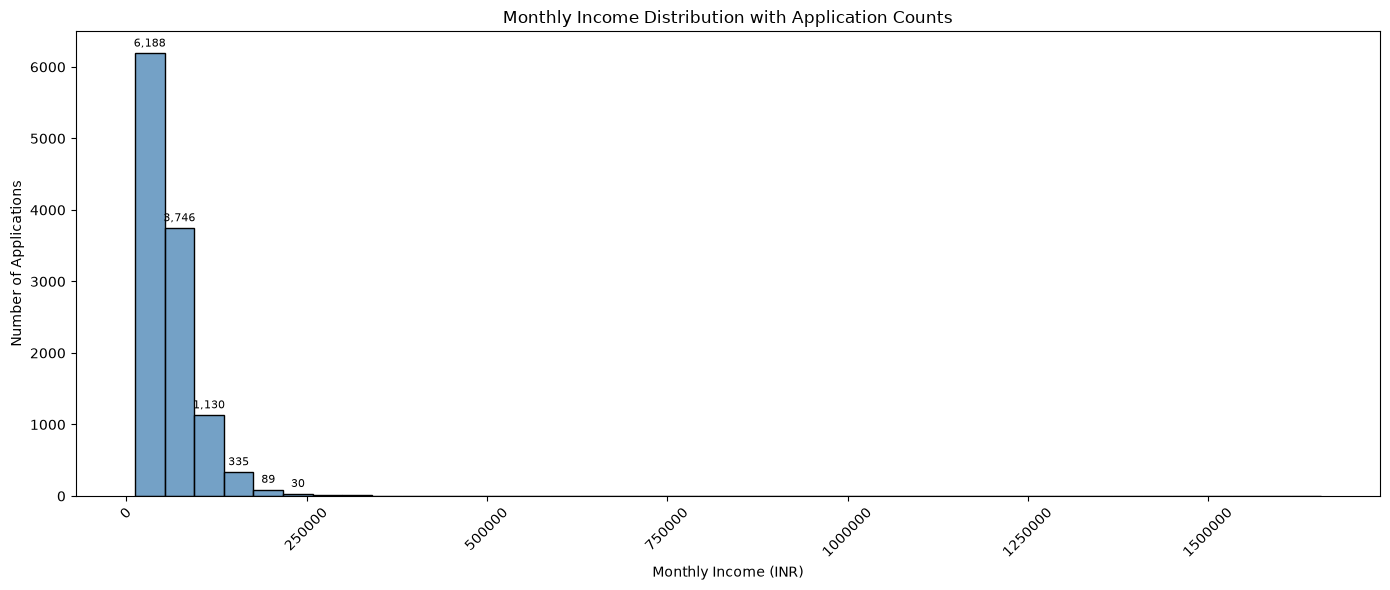

In [9]:
# Plot monthly income distribution with counts
plt.figure(figsize=(14, 6))

ax = sns.histplot(
    data=df_clean,
    x="monthly_income",
    bins=40,
    color="steelblue",
    edgecolor="black"
)

# Add counts above bars with enough observations
for patch in ax.patches:
    height = patch.get_height()

    if height >= 20:
        ax.annotate(
            f"{int(height):,}",
            (
                patch.get_x() + patch.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )

plt.title("Monthly Income Distribution with Application Counts")
plt.xlabel("Monthly Income (INR)")
plt.ylabel("Number of Applications")
plt.ticklabel_format(style="plain", axis="x")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Interpretation

The histogram shows how applications are distributed across monthly-income intervals. The labels indicate the number of applications in bins containing at least 20 records; smaller bins are left unlabelled to avoid clutter.

I will use this plot together with the descriptive statistics and highest-income records to assess whether the income distribution has a long upper tail. A long upper tail indicates extreme values but does not automatically mean those values are data errors.

-------------------------------------------------------------------------------------------------------------------------------

#### Examine Monthly Income on a Logarithmic Scale

The ordinary histogram may compress most applications into a small portion of the chart because a few income values are much larger than the rest. A logarithmic x-axis makes it easier to examine the distribution across a wider range of income values.

I will annotate the bars with their application counts and use this chart alongside the original-scale histogram. The logarithmic scale changes the visual spacing of income values, not the underlying data.

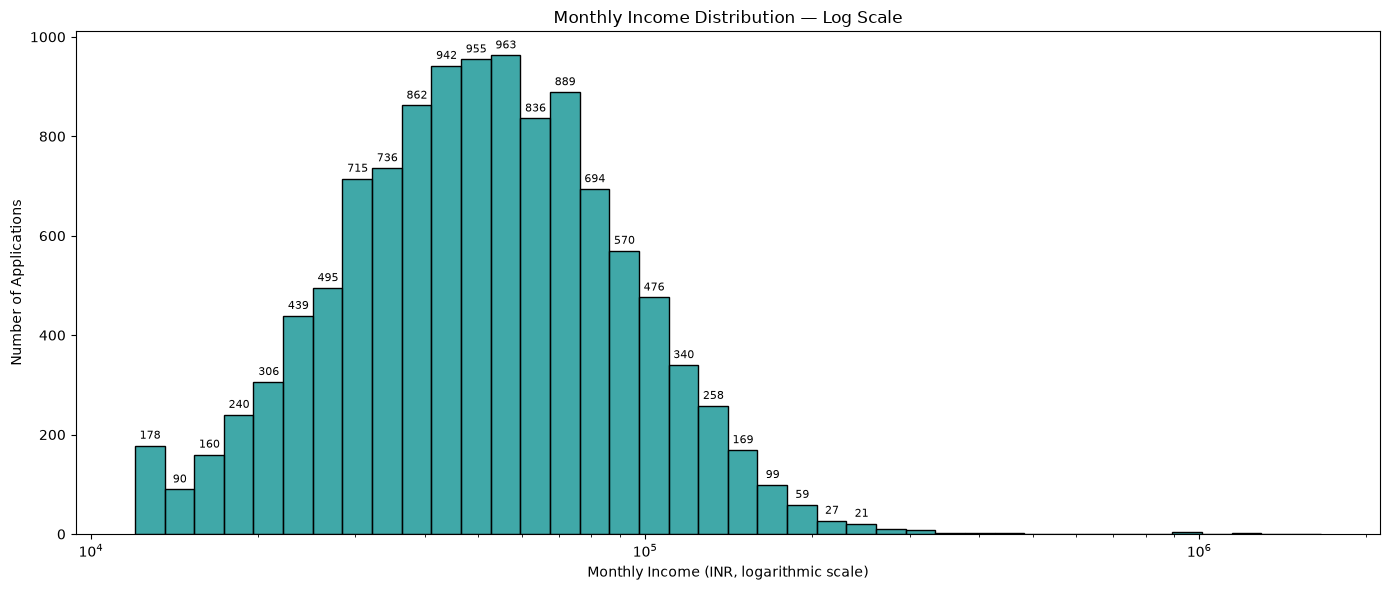

In [10]:
plt.figure(figsize=(14, 6))

ax = sns.histplot(
    data=df_clean,
    x="monthly_income",
    bins=40,
    log_scale=True,
    color="darkcyan",
    edgecolor="black"
)

# Label bars with at least 20 applications
for patch in ax.patches:
    height = patch.get_height()

    if height >= 20:
        ax.annotate(
            f"{int(height):,}",
            (
                patch.get_x() + patch.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )

plt.title("Monthly Income Distribution — Log Scale")
plt.xlabel("Monthly Income (INR, logarithmic scale)")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

#### Interpretation

The log-scale histogram allows the distribution of lower and higher income values to be inspected more clearly. Bar labels show counts for bins containing at least 20 applications.

The original-scale and log-scale charts should be interpreted together. Neither chart establishes whether the high values are incorrect; that conclusion would require additional evidence or confirmation of the units used when the data was recorded.

----------------------------------------------------------------------------------------------------------------------------------

#### Quantify Potentially Unusual Income Values

I will calculate the number and percentage of applications above selected income thresholds and inspect the relevant records. These thresholds are exploratory checks, not automatic rules for deleting or correcting income values.

The results will help quantify how many applications warrant further investigation.

In [11]:
# Exploratory income thresholds (INR per month)
income_thresholds = [200000, 300000, 500000, 1000000]

threshold_summary = pd.DataFrame({
    "Income_Threshold": income_thresholds,
    "Application_Count": [
        df_clean["monthly_income"].gt(threshold).sum()
        for threshold in income_thresholds
    ]
})

threshold_summary["Percentage"] = (
    threshold_summary["Application_Count"]
    / len(df_clean) * 100
).round(2)

display(threshold_summary)

,Income_Threshold,Application_Count,Percentage
0,200000,93,0.78
1,300000,28,0.23
2,500000,13,0.11
3,1000000,4,0.03


#### Findings and Interpretation

The threshold summary quantifies the number and proportion of applicants whose recorded monthly income exceeds each exploratory threshold.

These counts help prioritise records for investigation. The thresholds are not legal or banking limits, and values above them must not automatically be treated as errors. I will preserve the recorded values unless there is evidence that a specific record is incorrect.

--------------------------------------------------------------------------------------------------------------------

### Check Duplicates and Target Validity

Duplicate records can distort statistical analysis and model evaluation. I will check for fully duplicated rows and duplicate application identifiers. I will also verify that the decision target contains no missing values and only the expected labels, Approved and Declined.

I will not remove records unless these checks identify a genuine data-quality problem.

In [12]:
print("Duplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate application IDs:",
    df_clean["application_id"].duplicated().sum()
)

print(
    "Missing decision values:",
    df_clean["decision"].isna().sum()
)

print("\nDecision counts:")
display(
    df_clean["decision"]
    .value_counts(dropna=False)
    .rename_axis("Decision")
    .reset_index(name="Application_Count")
)

# Check for unexpected decision labels
expected_labels = {"Approved", "Declined"}

unexpected_labels = (
    set(df_clean["decision"].dropna().unique())
    - expected_labels
)

print("Unexpected decision labels:", unexpected_labels)

Duplicate rows: 0
Duplicate application IDs: 0
Missing decision values: 0

Decision counts:


,Decision,Application_Count
0,Approved,6353
1,Declined,5647


Unexpected decision labels: set()


#### Findings and Cleaning Decision

The initial inspection found no duplicate rows, duplicate application IDs, or missing decision labels. The target contains the expected Approved and Declined categories.

No rows need to be removed based on these checks. The application_id column will be retained for tracking and auditing, but it will not be used as a model feature.

-----------------------------------------------------------------------------------------------------------------------------------

### Calculate the Overall Approval Rate

The approval rate measures the proportion of applications historically approved by the credit team. The decline rate measures the proportion declined.

I will calculate the number and percentage of applications in each category. These results help assess the target distribution before classification modelling.

In [13]:
# Calculate decision counts
decision_counts = (
    df_clean["decision"]
    .value_counts()
    .reindex(["Approved", "Declined"], fill_value=0)
)

# Calculate decision percentages
decision_percentages = (
    decision_counts / len(df_clean) * 100
).round(2)

# Create summary table
decision_summary = pd.DataFrame({
    "Application_Count": decision_counts,
    "Percentage": decision_percentages
})

display(decision_summary)

# Calculate approval and decline rates
approval_rate = (
    df_clean["decision"].eq("Approved").mean() * 100
)

decline_rate = (
    df_clean["decision"].eq("Declined").mean() * 100
)

print(f"Overall approval rate: {approval_rate:.2f}%")
print(f"Overall decline rate: {decline_rate:.2f}%")

,Application_Count,Percentage
decision,,
Approved,6353,52.94
Declined,5647,47.06


Overall approval rate: 52.94%
Overall decline rate: 47.06%


#### Visualise Historical Loan Decisions

I will create a bar chart showing the number of Approved and Declined applications. Each bar will display both its application count and percentage, making the target distribution easy to compare visually and numerically.

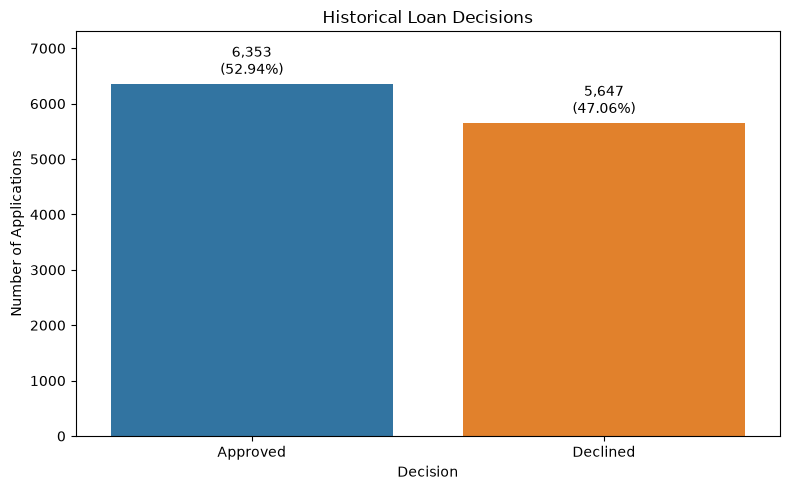

In [14]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="decision",
    order=["Approved", "Declined"],
    hue="decision",
    legend=False
)

# Add counts and percentages above the bars
total_applications = len(df_clean)

for patch in ax.patches:
    count = int(patch.get_height())
    percentage = count / total_applications * 100

    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        (
            patch.get_x() + patch.get_width() / 2,
            patch.get_height()
        ),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Historical Loan Decisions")
plt.xlabel("Decision")
plt.ylabel("Number of Applications")
plt.ylim(0, max(decision_counts) * 1.15)
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The dataset contains 6,353 Approved applications (52.94%) and 5,647 Declined applications (47.06%), out of 12,000 applications.

The target is reasonably balanced, with no severe class imbalance based on the overall proportions. However, model evaluation must consider the consequences of false declines and false approvals rather than relying on accuracy alone.

------------------------------------------------------------------------------------------------------------

### Convert Application Date to Datetime

The application_date column represents dates but may initially be stored as text. I will convert it to a datetime type and check for invalid dates and the observed date range.

The assignment excludes application_date from model features, so this conversion is for data consistency and potential chronological analysis.

In [15]:
# Convert dates to datetime
df_clean["application_date"] = pd.to_datetime(
    df_clean["application_date"],
    errors="coerce"
)

print(
    "Application date data type:",
    df_clean["application_date"].dtype
)

print(
    "Invalid or missing dates:",
    df_clean["application_date"].isna().sum()
)

print(
    "Earliest application date:",
    df_clean["application_date"].min()
)

print(
    "Latest application date:",
    df_clean["application_date"].max()
)

Application date data type: datetime64[us]
Invalid or missing dates: 0
Earliest application date: 2026-04-01 00:00:00
Latest application date: 2026-09-30 00:00:00


#### Findings and Cleaning Decision

The application_date column has been converted to datetime format. I will verify that the date range is consistent with the documented April–September 2026 period and check whether any dates became missing during conversion.

The date column will not be used as a model feature. Any invalid dates identified will be investigated rather than silently corrected.

----------------------------------------------------------------------------------------------------------------------------

### Final Data-Quality Verification

I will perform a final check of the working DataFrame to confirm its dimensions, data types, remaining missing values, and duplicate counts. This provides a concise record of the dataset's current state after the inspection and date conversion.

Missing values that have not yet been imputed will remain visible and documented. The income anomaly investigation is also considered unresolved until supporting evidence justifies a correction.

In [16]:
print("Dataset shape:", df_clean.shape)

print("\nData types:")
display(df_clean.dtypes.rename("Data_Type").to_frame())

print("\nRemaining missing values:")
remaining_missing = (
    df_clean.isnull()
    .sum()
    .rename("Missing_Count")
)

display(
    remaining_missing[remaining_missing > 0].to_frame()
)

print("\nDuplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate application IDs:",
    df_clean["application_id"].duplicated().sum()
)

Dataset shape: (12000, 19)

Data types:


,Data_Type
application_id,str
application_date,datetime64[us]
age,int64
gender,str
city,str
city_tier,int64
employment_type,str
years_in_current_job,float64
monthly_income,float64
existing_emi,float64



Remaining missing values:


,Missing_Count
monthly_income,441
credit_score,1039



Duplicate rows: 0
Duplicate application IDs: 0


### Step 5.1 — Conclusion

The dataset has been loaded and inspected for shape, data types, missing values, duplicates, target validity, and overall approval rate.

The 441 missing monthly_income values are concentrated among business owners and self-employed professionals. Employment-type median imputation is the proposed strategy, with final imputation to be learned from training data only.

The 1,039 missing credit scores are associated with zero credit-history months. These applicants will be retained as new-to-credit applicants, represented by an is_ntc indicator, and their missing scores will be imputed during model preprocessing.

The maximum recorded monthly income of ₹16,56,000 is unusually high compared with the median of ₹50,500. A possible unit error requires investigation; the values will not be automatically deleted, capped, or corrected without evidence.

The historical approval rate is 52.94%, and the decline rate is 47.06%. The target is reasonably balanced. The findings from this step will guide the approval-pattern analysis in Step 5.2 and the preprocessing pipeline used for model development.

In [17]:
# Step 5.1: Final validation checks

expected_columns = 19
expected_rows = 12000
expected_decisions = {"Approved", "Declined"}

validation_results = {
    "Expected dataset shape": (
        df_clean.shape == (expected_rows, expected_columns)
    ),
    "No duplicate rows": (
        df_clean.duplicated().sum() == 0
    ),
    "No duplicate application IDs": (
        df_clean["application_id"].duplicated().sum() == 0
    ),
    "No missing application IDs": (
        df_clean["application_id"].isna().sum() == 0
    ),
    "No missing target labels": (
        df_clean["decision"].isna().sum() == 0
    ),
    "Only expected target labels": (
        set(df_clean["decision"].unique()) == expected_decisions
    ),
    "Application dates converted": (
        pd.api.types.is_datetime64_any_dtype(
            df_clean["application_date"]
        )
    ),
    "Missing scores have zero credit history": (
        df_clean.loc[
            df_clean["credit_score"].isna(),
            "credit_history_months"
        ].eq(0).all()
    ),
    "Missing income count matches inspection": (
        df_clean["monthly_income"].isna().sum() == 441
    ),
    "Missing credit score count matches inspection": (
        df_clean["credit_score"].isna().sum() == 1039
    )
}

validation_summary = pd.DataFrame({
    "Validation": list(validation_results.keys()),
    "Passed": list(validation_results.values())
})

display(validation_summary)

print(
    f"\nOverall result: "
    f"{sum(validation_results.values())}/"
    f"{len(validation_results)} checks passed."
)

if not all(validation_results.values()):
    print("Review the failed checks before marking Step 5.1 complete.")
else:
    print("All validation checks passed.")

,Validation,Passed
0,Expected dataset shape,True
1,No duplicate rows,True
2,No duplicate application IDs,True
3,No missing application IDs,True
4,No missing target labels,True
5,Only expected target labels,True
6,Application dates converted,True
7,Missing scores have zero credit history,True
8,Missing income count matches inspection,True
9,Missing credit score count matches inspection,True



Overall result: 10/10 checks passed.
All validation checks passed.


## 5.2  What drives approval today?

In [18]:
# Step 5.2.1: Create credit-score bands

score_bins = [-np.inf, 600, 650, 700, 750, 800, np.inf]

score_labels = [
    "Below 600",
    "600–649",
    "650–699",
    "700–749",
    "750–799",
    "800+"
]

df_clean["credit_score_band"] = pd.cut(
    df_clean["credit_score"],
    bins=score_bins,
    labels=score_labels,
    right=False
)

# Add a separate category for applicants without a credit score
df_clean["credit_score_band"] = (
    df_clean["credit_score_band"]
    .cat.add_categories(["No score"])
    .fillna("No score")
)

# Display application counts in each band
score_band_counts = (
    df_clean["credit_score_band"]
    .value_counts()
    .reindex(score_labels + ["No score"], fill_value=0)
    .rename_axis("Credit_Score_Band")
    .reset_index(name="Application_Count")
)

display(score_band_counts)

# Verify that every application belongs to exactly one band
print("Total applications across bands:", score_band_counts["Application_Count"].sum())
print("Total dataset applications:", len(df_clean))

,Credit_Score_Band,Application_Count
0,Below 600,246
1,600–649,933
2,650–699,2529
3,700–749,3377
4,750–799,2526
5,800+,1350
6,No score,1039


Total applications across bands: 12000
Total dataset applications: 12000


### Step 5.2.1 — Create Credit-Score Bands

**Objective:** Categorize applicants into the six required credit-score ranges and a separate `No score` category.

The `credit_score` column is divided into the following groups: Below 600, 600–649, 650–699, 700–749, 750–799, and 800+. Applicants with missing credit scores are assigned to the `No score` group instead of being removed or treated as having a score of zero.

**Findings and interpretation:**

- The dataset contains **12,000 applications**, and the counts across all seven groups sum to 12,000.
- The largest group is the 700–749 band, with **3,377 applications**.
- The smallest group is the Below 600 band, with **246 applications**.
- There are **1,039 applicants without a recorded credit score**.

This grouping allows us to compare historical approval patterns across score ranges while keeping applicants without a recorded score separate.

In [19]:
# Step 5.2.2: Calculate approval rates by credit-score band

score_analysis = (
    df_clean.groupby("credit_score_band", observed=False)
    .agg(
        Total_Applications=("decision", "size"),
        Approved_Applications=(
            "decision",
            lambda s: s.eq("Approved").sum()
        ),
        Declined_Applications=(
            "decision",
            lambda s: s.eq("Declined").sum()
        )
    )
    .reindex(score_labels + ["No score"])
    .reset_index()
)

score_analysis["Approval_Rate_Pct"] = (
    score_analysis["Approved_Applications"]
    / score_analysis["Total_Applications"].replace(0, np.nan)
    * 100
).round(2)

score_analysis["Decline_Rate_Pct"] = (
    score_analysis["Declined_Applications"]
    / score_analysis["Total_Applications"].replace(0, np.nan)
    * 100
).round(2)

display(score_analysis)

,credit_score_band,Total_Applications,Approved_Applications,Declined_Applications,Approval_Rate_Pct,Decline_Rate_Pct
0,Below 600,246,5,241,2.03,97.97
1,600–649,933,30,903,3.22,96.78
2,650–699,2529,822,1707,32.50,67.50
3,700–749,3377,1836,1541,54.37,45.63
4,750–799,2526,1950,576,77.20,22.80
5,800+,1350,1150,200,85.19,14.81
6,No score,1039,560,479,53.90,46.10


### Step 5.2.2 — Calculate Historical Approval Rates by Credit-Score Band

**Objective:** Calculate the total, approved, and declined applications and the corresponding approval and decline rates for each credit-score band.

**Findings and interpretation:**

- The approval rate for applicants scoring below 600 is **2.03%**, with 5 approvals out of 246 applications.
- Applicants scoring 600–649 have an approval rate of **3.22%**, with 30 approvals out of 933 applications.
- The approval rate increases to **32.50%** for scores between 650 and 699 and **54.37%** for scores between 700 and 749.
- Applicants scoring 750–799 have an approval rate of **77.20%**, while those scoring 800 or above have the highest rate at **85.19%**.
- Applicants in the `No score` category have an approval rate of **53.90%**, with 560 approvals out of 1,039 applications.

Overall, the results show a strong positive association between observed credit-score bands and historical approval rates. The very low approval rates below 650 suggest a possible historical credit-score threshold, although the data does not establish a formal cutoff.

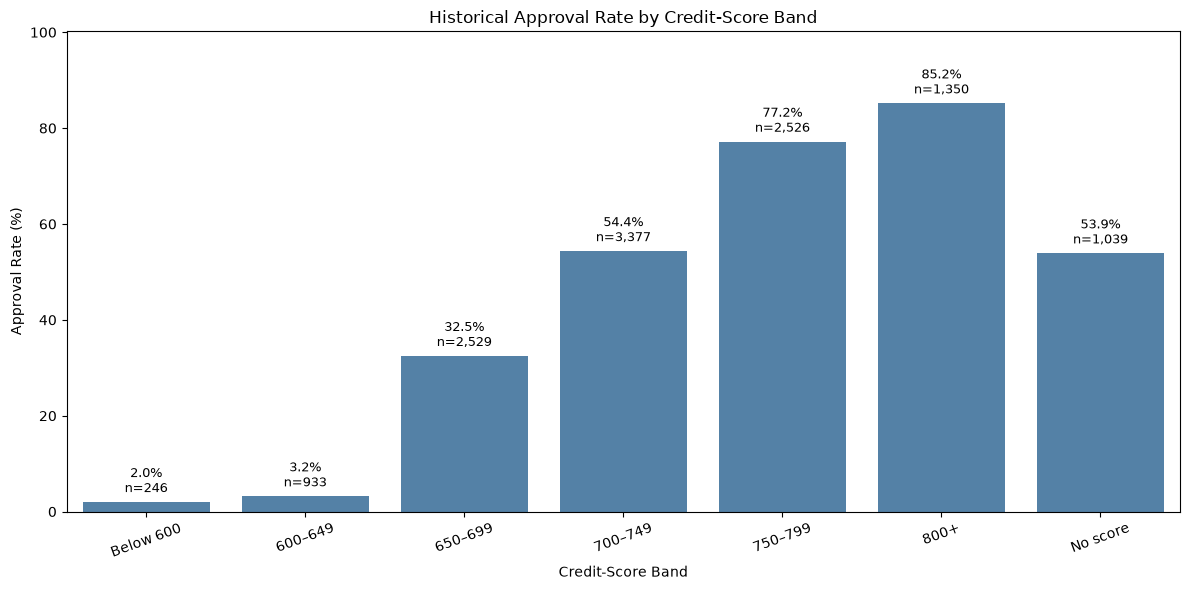

In [20]:
# Step 5.2.3: Plot approval rates by credit-score band

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=score_analysis,
    x="credit_score_band",
    y="Approval_Rate_Pct",
    color="steelblue"
)

for i, row in score_analysis.iterrows():
    if pd.notna(row["Approval_Rate_Pct"]):
        ax.annotate(
            f'{row["Approval_Rate_Pct"]:.1f}%\n'
            f'n={int(row["Total_Applications"]):,}',
            (i, row["Approval_Rate_Pct"]),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.title("Historical Approval Rate by Credit-Score Band")
plt.xlabel("Credit-Score Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(
    0,
    min(110, score_analysis["Approval_Rate_Pct"].max() + 15)
)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 5.2.3 — Visualise Approval Rates by Credit-Score Band

**Objective:** Use a bar chart to compare historical approval rates across credit-score bands. Each bar displays the approval percentage and the number of applications in that group.

**Findings and interpretation:**

The chart shows that approval rates generally increase as credit scores rise. The two lowest bands have approval rates of only **2.03% and 3.22%**, followed by a substantial increase in the 650–699 band to 32.50%.

The highest approval rate is observed in the 800+ band at **85.19%**. The `No score` group has an approval rate of **53.90%**, which is much higher than the rates for applicants scoring below 650.

This visual pattern suggests that the bank's historical decisions strongly distinguish applicants with very low credit scores from applicants with higher scores or no recorded score. However, approval rates alone cannot establish the bank's formal policy or the applicants' future repayment performance.

In [21]:
# Step 5.2.4: Calculate approval rates by employment type

employment_analysis = (
    df_clean.groupby("employment_type", dropna=False)
    .agg(
        Total_Applications=("decision", "size"),
        Approved_Applications=(
            "decision",
            lambda s: s.eq("Approved").sum()
        ),
        Declined_Applications=(
            "decision",
            lambda s: s.eq("Declined").sum()
        )
    )
    .reset_index()
)

employment_analysis["Approval_Rate_Pct"] = (
    employment_analysis["Approved_Applications"]
    / employment_analysis["Total_Applications"]
    * 100
).round(2)

employment_analysis["Decline_Rate_Pct"] = (
    employment_analysis["Declined_Applications"]
    / employment_analysis["Total_Applications"]
    * 100
).round(2)

employment_analysis = employment_analysis.sort_values(
    "Approval_Rate_Pct",
    ascending=False
)

display(employment_analysis)

,employment_type,Total_Applications,Approved_Applications,Declined_Applications,Approval_Rate_Pct,Decline_Rate_Pct
2,Salaried,7057,4119,2938,58.37,41.63
0,Business Owner,1749,895,854,51.17,48.83
3,Self-Employed Professional,1428,722,706,50.56,49.44
1,Gig / Contract,1766,617,1149,34.94,65.06


### Step 5.2.4 — Calculate Historical Approval Rates by Employment Type

**Objective:** Compare total applications, approved applications, declined applications, and approval and decline rates across employment categories.

**Findings and interpretation:**

- **Salaried:** 4,119 of 7,057 applications were approved, resulting in an approval rate of **58.37%**.
- **Business Owner:** 895 of 1,749 applications were approved, resulting in an approval rate of **51.17%**.
- **Self-Employed Professional:** 722 of 1,428 applications were approved, resulting in an approval rate of **50.56%**.
- **Gig / Contract:** 617 of 1,766 applications were approved, resulting in the lowest approval rate of **34.94%**.

Salaried applicants have the highest historical approval rate, while Gig / Contract applicants have the lowest. The difference is **23.43 percentage points**.

These differences indicate that historical approval outcomes vary by employment category. However, employment type alone may not explain the differences; income, credit score, existing financial commitments, and other applicant characteristics may also contribute.

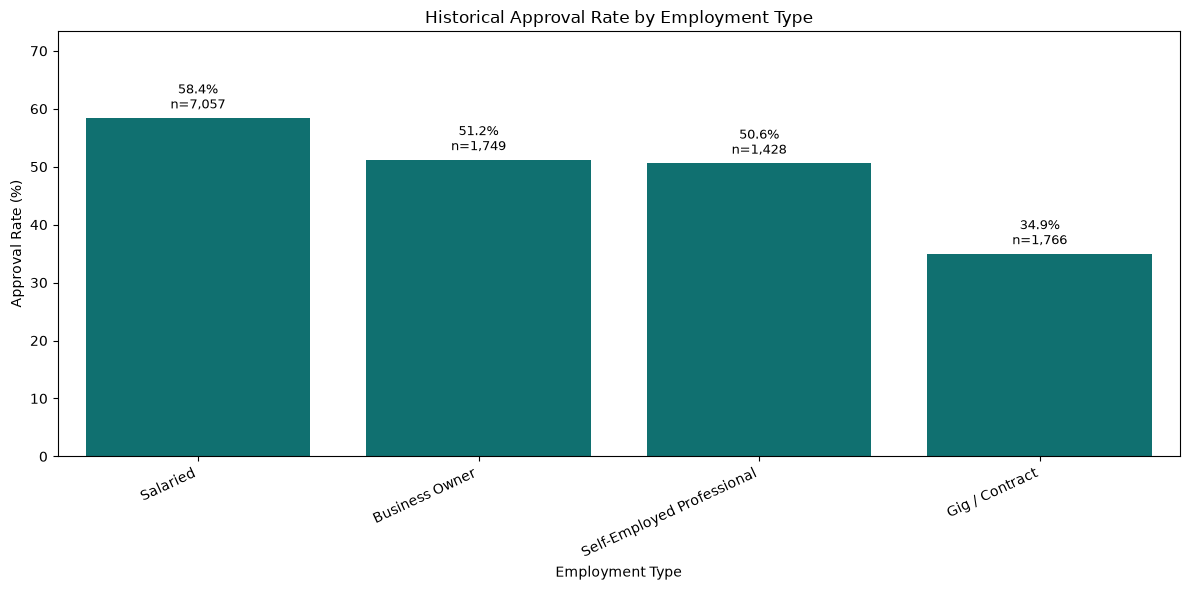

In [22]:
# Step 5.2.5: Plot approval rates by employment type

employment_plot = employment_analysis.reset_index(drop=True)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=employment_plot,
    x="employment_type",
    y="Approval_Rate_Pct",
    color="teal"
)

for i, row in employment_plot.iterrows():
    ax.annotate(
        f'{row["Approval_Rate_Pct"]:.1f}%\n'
        f'n={int(row["Total_Applications"]):,}',
        (i, row["Approval_Rate_Pct"]),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Historical Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.ylim(
    0,
    min(110, employment_plot["Approval_Rate_Pct"].max() + 15)
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Step 5.2.5 — Visualise Approval Rates by Employment Type

**Objective:** Display the historical approval rate for each employment category using a bar chart. The percentage and application count are shown above each bar to support clear comparisons.

**Findings and interpretation:**

The chart confirms that salaried applicants have the highest historical approval rate at **58.37%**, followed by Business Owners at **51.17%** and Self-Employed Professionals at **50.56%**. Gig / Contract applicants have the lowest approval rate at **34.94%**.

The lower approval rate for Gig / Contract applicants suggests that historical lending outcomes differ across employment categories. This difference warrants further investigation, particularly to determine whether it is associated with differences in income stability, credit history, financial obligations, or other relevant characteristics.

The chart identifies an association, not a causal relationship or proof of unfair treatment.

In [23]:
# Step 5.2.6: Validate approval analysis

print("Credit-score band checks")
print(
    "Applications accounted for:",
    score_analysis["Total_Applications"].sum()
)
print("Dataset applications:", len(df_clean))

print(
    "Approved count matches dataset:",
    score_analysis["Approved_Applications"].sum()
    == df_clean["decision"].eq("Approved").sum()
)

print(
    "Declined count matches dataset:",
    score_analysis["Declined_Applications"].sum()
    == df_clean["decision"].eq("Declined").sum()
)

print("\nEmployment-type checks")
print(
    "Applications accounted for:",
    employment_analysis["Total_Applications"].sum()
)
print("Dataset applications:", len(df_clean))

print(
    "Employment approval counts match dataset:",
    employment_analysis["Approved_Applications"].sum()
    == df_clean["decision"].eq("Approved").sum()
)

print(
    "Employment decline counts match dataset:",
    employment_analysis["Declined_Applications"].sum()
    == df_clean["decision"].eq("Declined").sum()
)

Credit-score band checks
Applications accounted for: 12000
Dataset applications: 12000
Approved count matches dataset: True
Declined count matches dataset: True

Employment-type checks
Applications accounted for: 12000
Dataset applications: 12000
Employment approval counts match dataset: True
Employment decline counts match dataset: True


### Step 5.2.6 — Validate Approval Analysis

**Objective:** Verify that all applications are represented in the credit-score and employment-type analyses, and confirm that the approved and declined application counts match the original dataset.

**Validation results:**

- The credit-score band analysis accounts for all **12,000 applications**.
- The employment-type analysis also accounts for all **12,000 applications**.
- The total approved counts match the original dataset.
- The total declined counts match the original dataset.
- All validation checks returned `True`.

**Interpretation:**

The validation results confirm that both analyses account for the complete dataset and that the approval and decline counts reconcile with the original decision labels. This supports the reliability of the calculations used in the tables and visualisations.

----------------------------------------------------------------------------------------------------------------

### Step 5.2 — Overall Conclusion: What Drives Historical Approval?

The analysis reveals a strong association between credit score and historical loan approval. Applicants scoring below 650 have very low approval rates of **2.03% and 3.22%**, suggesting a possible historical credit-score threshold, although 35 applicants in these bands were approved. Applicants with no recorded credit score have a substantially higher approval rate of **53.90%**, indicating that missing scores should not automatically be treated as poor scores. Approval rates also vary by employment type: salaried applicants have the highest rate at **58.37%**, while Gig / Contract applicants have the lowest at **34.94%**. These patterns provide useful context for feature engineering and model development, but historical decisions do not necessarily represent actual creditworthiness or future repayment outcomes. The next step is to investigate financial-obligation features and their relationship with historical approval decisions.